# BankSim: Fraud Detection with Global and Customer-Context Anomalies

### Business problem
A bank can manually investigate **at most 1% of transactions** in each evaluation period. Your goal is to rank transactions by suspicion using **unsupervised anomaly detection**. Compare:
- a custom **k-nearest-neighbor (kNN) distance anomaly score**, and
- **Isolation Forest**.

BankSim contains **simulated** card transactions. Its patterns are inspired by aggregated banking behavior; it is not a collection of genuine individual banking transactions.

You will investigate whether a transaction that appears ordinary in the **overall population** can still be unusual **relative to that customer's previous behavior**.

### Rules for a valid solution
1. **Use all rows.** Do not sample the dataset or restrict the kNN reference set. You may process queries in batches for memory efficiency.
2. Use the supplied **chronological train / validation / test split**. Do not change it.
3. **Fit unsupervised models without using `fraud` labels.** Validation labels may be used to compare experiments and choose a final configuration. Test labels may be used **only once, after your final choice is frozen**.
4. Do not use a transaction's future or same-time-step transactions when computing its historical customer profile. `step` is a discrete time index; transactions with equal `step` are treated as simultaneous.
5. Document **at least three controlled experiments** in Task 4, including a required context/no-context comparison. Your Task 5 choice must come **from these experiments** - do not run a new parameter search in Task 5.
6. Explain your reasoning even if a hypothesis is rejected. A higher score is not automatically a better scientific conclusion.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, confusion_matrix

SEED = 42
DATA_FILE = Path("bs140513_032310.csv")
if not DATA_FILE.is_file():
    raise FileNotFoundError("Place bs140513_032310.csv next to this notebook.")
raw = pd.read_csv(DATA_FILE)
raw.columns = raw.columns.str.strip()
raw = raw.sort_values("step", kind="stable").reset_index(drop=True)
print(f"Transactions: {len(raw):,}; fraud cases: {int(raw.fraud.sum()):,}")
display(raw.head())

Transactions: 594,643; fraud cases: 7,200


,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


## Task 1 - Exploratory analysis, customer history and hypotheses (3 points, ~30 min)

### 1A. Explore the dataset
Report:
- the fraud rate and why accuracy alone is unsuitable;
- the amount distributions and at least one difference between transaction categories;
- how many transactions customers have, including whether some customers have little history;
- **at least two interpreted observations** relevant to anomaly detection.

You may inspect `fraud` during EDA to understand the dataset and propose hypotheses. **Do not use it to construct anomaly features or fit the unsupervised models.**

### 1B. Construct a historical customer reference
A **customer context** is the typical behavior of **that specific customer**, rather than typical behavior across the entire bank.

Example: a payment of 300 units might be routine for a customer who previously spent around 250-350, but exceptional for a customer who previously spent around 10-20. A global amount score sees only 300; a context feature compares 300 with **earlier amounts for that customer**.

Implement **one historical amount statistic** for each transaction, such as the customer's mean or median of **strictly earlier-step transactions**. The choice and implementation are yours.

**Required temporal rule:** For a transaction with customer `c` and step `t`, its reference statistic can use only rows with `customer == c` **and `step < t`**. Do not include the current transaction, any other transaction from step `t`, or future steps. A simple `groupby('customer')['amount'].transform('mean')` on the entire table is **not valid**.

Store your result in `raw["customer_history"]` and record how many earlier transactions contributed in `raw["history_count"]`. For a customer without prior transactions, use `NaN` for the statistic and `0` for the count. **Do not impute yet**; you will choose a defensible policy in Task 4.

A practical approach is to first aggregate each `(customer, step)` group and then compute the history from preceding groups. Explain how your approach enforces the strict `< step` condition.

### 1C. State exactly two testable hypotheses
At least **one** must concern customer context. For each hypothesis, specify:
- expected direction of change;
- metric used to test it;
- which experimental settings must remain fixed.

Total transactions: 594643
Total fraud cases: 7200
Fraud rate: 1.21%

Amount summary:


fraud,0,1
count,587443.000000,7200.000000
mean,31.847230,530.926551
std,31.470876,835.587112
min,0.000000,0.030000
25%,13.590000,159.980000
50%,26.610000,319.175000
75%,41.895000,548.977500
max,2144.860000,8329.960000



Category differences:


,total_count,fraud_count,fraud_rate,mean_amount
category,,,,
'es_leisure',499,474,0.949900,288.911303
'es_travel',728,578,0.793956,2250.409190
'es_sportsandtoys',4002,1982,0.495252,215.715280
'es_hotelservices',1744,548,0.314220,205.614249
'es_otherservices',912,228,0.250000,135.881524
'es_home',1986,302,0.152064,165.670846
'es_health',16133,1696,0.105126,135.621367
'es_tech',2370,158,0.066667,120.947937
'es_wellnessandbeauty',15086,718,0.047594,65.511221



Customer transaction grouped by count:


count    4112.000000
mean      144.611625
std        42.788212
min         5.000000
25%       130.000000
50%       165.000000
75%       173.000000
max       265.000000
dtype: float64

Number of customers with transactions less than 10: 32
Total customers: 4112


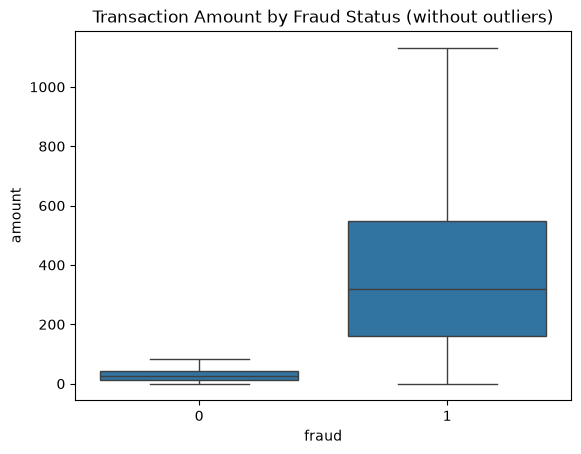

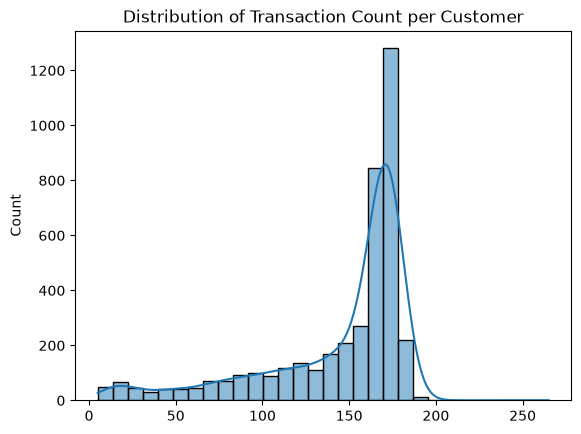

In [23]:
# TODO 1A - Exploratory analysis and interpreted observations.
# Add code, plots/tables and written conclusions below.
import matplotlib.pyplot as plt
import seaborn as sns

total_transactions = len(raw)
print(f"Total transactions: {total_transactions}")

total_fraud = raw["fraud"].sum()
print(f"Total fraud cases: {total_fraud}")

fraud_rate = total_fraud / total_transactions
print(f"Fraud rate: {fraud_rate:.2%}")

print("\nAmount summary:")
amount_summary = raw.groupby("fraud")["amount"].describe().T
display(amount_summary)


print("\nCategory differences:")
catergory_summary = (
    raw.groupby("category")
    .agg(
        total_count=("fraud", "count"),
        fraud_count=("fraud", "sum"),
        fraud_rate=("fraud", "mean"),
        mean_amount=("amount", "mean"),
    )
    .sort_values(["fraud_rate", "fraud_count"], ascending=False)
)
display(catergory_summary)


print("\nCustomer transaction grouped by count:")
customer_transactions_count = raw.groupby("customer").size()
display(customer_transactions_count.describe())\

LOW_TRANSACTIONS_THREASHOLD = 10
customers_with_small_transactions_count = (customer_transactions_count <= LOW_TRANSACTIONS_THREASHOLD).sum()
print(f"Number of customers with transactions less than {LOW_TRANSACTIONS_THREASHOLD}: {customers_with_small_transactions_count}")
print(f"Total customers: {len(customer_transactions_count)}")


sns.boxplot(data=raw, x="fraud", y="amount", showfliers=False)
plt.title("Transaction Amount by Fraud Status (without outliers)")
plt.show()

sns.histplot(customer_transactions_count, bins=30, kde=True)
plt.title("Distribution of Transaction Count per Customer")
plt.show()

In [ ]:
# TODO 1B - Historical customer statistic and number of earlier transactions.
# Required output columns:
# raw["customer_history"]  # NaN if no earlier transactions
# raw["history_count"]     # 0 if no earlier transactions

# Your implementation here.

# Uncomment these checks after implementing the columns:
# assert len(raw["customer_history"]) == len(raw)
# assert raw["history_count"].ge(0).all()
# assert raw.loc[raw["history_count"].eq(0), "customer_history"].isna().all()
# assert raw.loc[raw.step.eq(raw.step.min()), "history_count"].eq(0).all()

**Your observations and hypotheses (write below):**

**Observation 1:** ...

**Observation 2:** ...

**Historical reference choice and leakage prevention:** ...

**Hypothesis H1 (direction, metric, controls):** ...

**Hypothesis H2 (direction, metric, controls):** ...

## Chronological split (do not modify)

The split is performed on **all 594,643 transactions**, using the ordered values of `step`. Approximately the first 60% of time steps form training, the next 20% validation and the final 20% test. Since time steps contain different numbers of transactions, row counts need not follow a 60/20/20 ratio.

The historical profile from Task 1 is allowed to use **earlier unlabeled transactions from the full log**, even if those transactions are not in the same split. This models information the bank would already have at transaction time. It must never use future amounts or fraud labels.

**Keep the test labels sealed:** The code below creates `test`, but do not inspect `test.fraud` or evaluate test predictions until Task 5.

In [ ]:
# PROVIDED - chronological split, full dataset, no sampling
steps = np.sort(raw.step.unique())
boundary1 = steps[int(len(steps) * 0.60)]
boundary2 = steps[int(len(steps) * 0.80)]
train = raw[raw.step < boundary1].copy()
val = raw[(raw.step >= boundary1) & (raw.step < boundary2)].copy()
test = raw[raw.step >= boundary2].copy()

assert train.step.max() < val.step.min() < test.step.min()
assert len(train) + len(val) + len(test) == len(raw)
for name, frame in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name}: {len(frame):,} transactions; steps {frame.step.min()}..{frame.step.max()}")

# Labels for VALIDATION only. Test labels are accessed in Task 5.
y_val = val["fraud"].to_numpy()

## Consistent feature preprocessing

The **global (non-contextual) baseline** is an anomaly detection model using only transaction `amount` and time `step`, without any customer-specific historical information.

Standardization parameters must be fitted on the **training set only**, then applied unchanged to validation and test.

When you create context features in Task 4, apply the same rule. Keep feature sets comparable: the required context experiment must differ from the baseline **only by the addition of your context feature(s)**.

**Do not include** `fraud`, raw `customer` IDs or raw `merchant` IDs as numeric distances. If you explore categorical variables, justify their encoding and computational cost.

In [ ]:
# PROVIDED - shared preprocessing for baseline and experimental feature sets
def scaled_features(columns):
    """Fit StandardScaler on training rows only; transform train/validation/test."""
    scaler = StandardScaler().fit(train[columns])
    return (
        scaler.transform(train[columns]),
        scaler.transform(val[columns]),
        scaler.transform(test[columns]),
    )

BASE_COLUMNS = ["amount", "step"]
X_train_base, X_val_base, X_test_base = scaled_features(BASE_COLUMNS)

## Task 2 - Implement a custom kNN anomaly score (1 point, ~20 min)

For every **query** transaction, return the Euclidean distance to its **k-th nearest neighbor among all training transactions**. Larger distance means a stronger anomaly.

You may use `sklearn.neighbors.NearestNeighbors` to search for neighbors, but **you must implement the anomaly-score calculation** (extract the k-th distance). You do **not** need to implement a search tree or a distance matrix yourself.

**Performance guidance:**
- Use `NearestNeighbors(algorithm="kd_tree", n_jobs=-1)` for the low-dimensional numeric features in this assignment. A KD-tree is a useful choice here, though not universally fastest in high-dimensional spaces.
- Fit the neighbor index **once per fixed training feature representation**, not once per query transaction. Query the whole validation set in **batches** (e.g. 10,000 rows) to control memory.
- If testing multiple values of `k` on identical features, you may query once with the **largest** `k` and reuse the returned distance columns.
- Validation and test rows are distinct from training rows, so you do not have to remove a self-neighbor in those queries. If you score training rows against themselves, you **must** exclude self-matches.

**Required function:** `custom_knn_score(reference, query, k=20)` returning one score per query row. Run it on the global baseline validation features.

In [ ]:
def custom_knn_score(reference, query, k=20):
    """TODO: return distance to k-th nearest training neighbor for each query row."""
    # Suggested: NearestNeighbors(n_neighbors=k, algorithm="kd_tree", n_jobs=-1)
    # Fit ONCE; query in batches; extract the last distance column.
    raise NotImplementedError

# TODO: score X_val_base against ALL X_train_base (e.g. k=20).
# knn_base_val = ...

## Task 3 - Isolation Forest and evaluation (2 points, ~20 min)

1. Fit an `IsolationForest` on `X_train_base` **without labels**.
2. Produce **continuous anomaly scores** for `X_val_base`, with **larger = more anomalous**. Important: In scikit-learn, lower values returned by `IsolationForest.score_samples()` indicate more anomalous observations. Negate these values so that higher anomaly scores consistently indicate more suspicious transactions, as in your kNN implementation.
3. Evaluate **both** methods using the **same validation period and investigation budget**.

### Evaluation protocol
- **Primary business metric:** `recall@1%` = fraction of all actual frauds captured among the **top 1% highest-scored validation transactions**.
- **Also report:** `precision@1%`, **Average Precision (AP)**, number of true-positive alerts, false-positive alerts, and total alerts.
- For a set with `N` rows, use exactly `floor(0.01 * N)` alerts. Ties may be broken deterministically by row order.
- The 1% investigation budget is **not** the assumed fraud prevalence and is **not** the `contamination` setting of Isolation Forest.
- AP uses **continuous scores**; precision@1% and recall@1% use the fixed top-1% alert list.

Use the supplied `evaluate_scores` helper. You are responsible for the Isolation Forest implementation and for interpreting the comparison.

In [ ]:
# PROVIDED - fixed-budget evaluation helper
def evaluate_scores(y_true, scores, budget=0.01):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if len(y_true) != len(scores) or not np.isfinite(scores).all():
        raise ValueError("Scores must be finite and match the label array.")
    n_alerts = int(np.floor(len(scores) * budget))
    predicted = np.zeros(len(scores), dtype=int)
    predicted[np.argsort(-scores, kind="stable")[:n_alerts]] = 1
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "AP": average_precision_score(y_true, scores),
        "precision_at_1pct": tp / n_alerts if n_alerts else 0.0,
        "recall_at_1pct": tp / (tp + fn) if tp + fn else 0.0,
        "TP": int(tp), "FP": int(fp), "FN": int(fn),
        "alerts": int(n_alerts),
    }

# TODO - Train Isolation Forest (e.g. 150 trees, max_samples=256, random_state=SEED).
# Use -model.score_samples(...) so larger scores mean more anomalous.
# if_base_val = ...

# TODO - Evaluate BOTH models on validation, using evaluate_scores(y_val, ...).
# Explain what the alert budget means for the bank.

## Task 4 - Customer-context feature and independent experiments (3 points, ~60 min)

### 4A. Create your own customer-context anomaly feature (1 point)

Use the historical statistic from Task 1 to express how unusual the **current transaction amount** is **relative to the same customer's earlier transactions**.

A **historical reference** and a **context anomaly feature** are different:
- **Historical reference:** a summary of earlier amounts for that customer, such as their prior mean or prior median. It does **not** use the current amount.
- **Context anomaly feature:** a comparison between the **current amount** and that historical reference. It **does** use the current amount, but never future amounts or fraud labels.

For instance, a ratio, difference or transformed deviation could be reasonable, but **you must choose, implement and justify your own formula**. Do not assume that a larger amount is automatically suspicious for every customer.

**Required edge cases:** Some customers have no earlier transactions (`history_count == 0`). Some reference amounts may be zero or very small. Explain and implement a safe policy. Any fallback value estimated from the population must be calculated on **training data only**. You may include a binary indicator of missing history.

Store your feature(s) in the `train`, `val`, and `test` frames, using identical transformations. **Do not use validation or test fraud labels** in feature engineering.

### 4B. Design and run at least THREE controlled experiments (2 points)

**Experiment 1 is mandatory:** Compare the global baseline (`amount`, `step`) with the **same baseline plus your context feature(s)**. Keep the model type, parameters, train/validation periods, scaling policy and 1% alert budget fixed. Run the comparison for **both kNN and Isolation Forest**.

**Experiments 2 and 3:** Choose your own meaningful research questions. Possible dimensions include kNN neighborhood size, Isolation Forest subsample size, or a justified alternative representation. These are **examples, not mandatory settings**. Each experiment must vary a clearly identified factor while keeping the rest controlled.

For **each experiment**, include:
1. **Question and expected direction** (connected to a hypothesis when appropriate).
2. **Independent variable** and **controlled settings**.
3. Reproducible code and a **validation-results table** (at minimum recall@1%, precision@1%, AP, and the full model configuration).
4. Interpretation of whether the result supports the hypothesis and why it might have occurred.

**Record each evaluated configuration and its validation metrics in `experiment_results`.** The final model in Task 5 **must be selected from these already evaluated configurations**. Do not launch a new grid search or new validation calculations in Task 5.

**Efficiency:** Reuse feature arrays, fitted models and neighbor indices where possible. Do not recompute identical configurations simply to populate tables. You may process kNN queries in batches, but must still score **all** validation transactions against **all** training transactions.

In [ ]:
# TODO 4A - Create your context feature(s) from customer_history and amount.
# Handle no-history and near-zero-history cases explicitly.
# Example column name: "customer_deviation" (formula is YOUR choice).
# Add the same feature column(s) to train, val and test.
# Then use scaled_features([...]) with baseline columns + your feature(s).

# X_train_ctx, X_val_ctx, X_test_ctx = ...

In [ ]:
# TODO 4B - Three controlled experiments.
# Use this suggested record format so Task 5 can select a winner
# without running additional validation experiments.

experiment_results = []

# After evaluating a configuration, append a record such as:
# experiment_results.append({
#     "experiment": "E1",
#     "model": "kNN",             # or "IsolationForest"
#     "feature_set": "baseline",  # or "context"
#     "params": {"k": 20},       # or {"n_estimators": 150, "max_samples": 256}
#     **evaluate_scores(y_val, scores_on_validation),
# })
#
# Keep feature-set definitions and exact parameter values in your records.
# Your three experiments may produce MORE than three configuration records.

# TODO - Implement experiments and display a consolidated validation table.

### Experiment report (complete all three)

| Experiment | Research question / expected direction | What changed? | What stayed fixed? | Main validation result | Interpretation |
|---|---|---|---|---|---|
| E1: context vs no context (both models) | ... | ... | ... | ... | ... |
| E2: your choice | ... | ... | ... | ... | ... |
| E3: your choice | ... | ... | ... | ... | ... |

**Hypothesis H1:** supported / not supported / inconclusive, because ...

**Hypothesis H2:** supported / not supported / inconclusive, because ...


## Task 5 - Choose a model from your experiments and make a recommendation (1 point, ~20 min)

**No new model search is allowed in this task.** Use the **validation table you already produced in Task 4** (including the baseline results from Task 3) to select **one previously evaluated** model, feature set and parameter configuration.

1. **Select and justify the winner using existing validation results.** Prioritize `recall@1%`, because only 1% of transactions can be investigated. Use AP, precision@1% and operational considerations to discuss close results or ties. State the exact winning feature set and hyperparameters.
2. **Freeze the choice.** Do not change it after seeing test results.
3. **Evaluate this single frozen configuration once on the untouched test set.** You may fit that selected configuration on the **original training split** and generate test scores. Do **not** repeat a parameter sweep or recompute validation scores here. Keep preprocessing fitted on training only.
4. Report test recall@1%, precision@1%, AP, number of alerts, true positives and false positives. Explain what these numbers mean for the bank.
5. Provide a concise recommendation, including at least one limitation. If test performance is weaker, explain the discrepancy; do not switch models.

**Important:** `experiment_results` is the record of what you have already tested. If it does not include the exact configuration you want to select, you cannot introduce that configuration now.

In [ ]:
# TODO - Select a previously evaluated configuration from experiment_results.
# You may sort/display existing records, but DO NOT run additional validation models.
#
# selected = ...
# print("Frozen configuration:", selected)
#
# TODO - Fit/use only the selected configuration, score X_test_base OR X_test_ctx,
# depending on the selected feature set.
# test_scores = ...
#
# NOW, and only now, reveal test labels:
# y_test = test["fraud"].to_numpy()
# display(pd.DataFrame([evaluate_scores(y_test, test_scores)]))

### Final recommendation (write below)

**Selected model, features and hyperparameters:** ...

**Evidence from the EXISTING validation experiments:** ...

**One-time test results (recall@1%, precision@1%, AP, TP, FP, alerts):** ...

**Recommendation for the bank:** ...

**Limitations and possible improvements:** ...
